Dataset loaded successfully.
Graph created successfully.
Number of users: 4039
Number of friendships: 88234

--- Top 5 Most Influential Users ---

Most Popular Users (Degree Centrality):
User 107: Centrality = 0.2588
User 1684: Centrality = 0.1961
User 1912: Centrality = 0.1870
User 3437: Centrality = 0.1355
User 0: Centrality = 0.0859

Best Connectors (Betweenness Centrality):
User 107: Centrality = 0.4907
User 1684: Centrality = 0.3607
User 1912: Centrality = 0.2261
User 3437: Centrality = 0.2142
User 0: Centrality = 0.1474

Fastest Information Spreaders (Closeness Centrality):
User 107: Centrality = 0.4597
User 58: Centrality = 0.3974
User 428: Centrality = 0.3948
User 563: Centrality = 0.3939
User 1684: Centrality = 0.3936


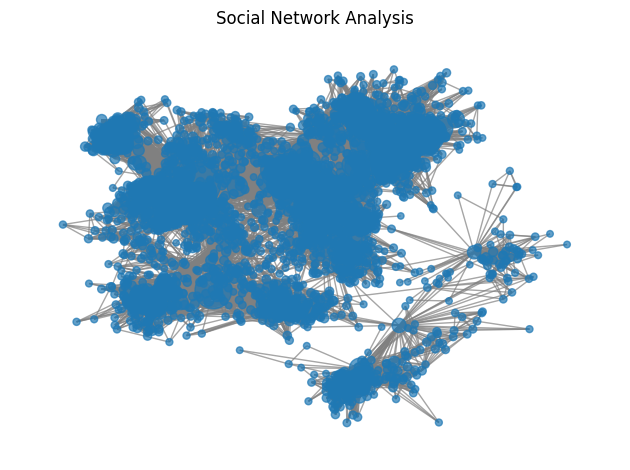

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# 1. Read dataset
df = pd.read_csv("facebook_combined.txt", sep=r"\s+",
                 header=None, names=["user_1", "user_2"])
df.dropna(inplace=True)
print("Dataset loaded successfully.")

# 2. Create graph
G = nx.from_pandas_edgelist(df, "user_1", "user_2")
print("Graph created successfully.")
print("Number of users:", G.number_of_nodes())
print("Number of friendships:", G.number_of_edges())

# 3. Calculate centrality
degree = nx.degree_centrality(G)
between = nx.betweenness_centrality(
    G, k=min(200, G.number_of_nodes()), seed=42)
close = nx.closeness_centrality(G)

# 4. Display top 5 users
print("\n--- Top 5 Most Influential Users ---")

for name, values in [
    ("Most Popular Users (Degree Centrality)", degree),
    ("Best Connectors (Betweenness Centrality)", between),
    ("Fastest Information Spreaders (Closeness Centrality)", close)
]:
    print("\n" + name + ":")
    for user, score in sorted(values.items(),
                              key=lambda x: x[1], reverse=True)[:5]:
        print(f"User {user}: Centrality = {score:.4f}")

# 5. Draw graph
pos = nx.spring_layout(G, seed=42, k=0.15)
sizes = [20 + 5000 * degree[n] for n in G.nodes()]

nx.draw_networkx(G, pos, with_labels=False,
                 node_size=sizes, edge_color="gray", alpha=0.7)

plt.title("Social Network Analysis")
plt.axis("off")
plt.tight_layout()
plt.show()